En este primer bloque de prácticas implementaremos sistemas basados en reglas a través de C Language Integrated Production System (CLIPS).

CLIPS es un lenguaje de programación basado en reglas útil para crear sistemas expertos y otros programas en los que una solución heurística es más fácil de implementar y mantener que una solución algorítmica. Escrito en C para mayor portabilidad, CLIPS puede instalarse y utilizarse en una amplia variedad de plataformas. Nosotros utilizaremos la librería Clipspy de Python que nos permite combinar código CLIPS y Python de forma fácil y cómoda.

Durante esta práctica cambiaremos de paradigma de la programación. A lo largo de las diferentes asignaturas habéis visto un paradigma imperativo. En esta práctica utilizaréis un paradigma declarativo. La diferencia entre código declarativo e imperativo es que el código imperativo contiene una secuencia explícita de comandos para describir cómo quieres que el programa haga las cosas, y el código declarativo especifica el resultado de lo que quieres, sin especificar los pasos exactos.


# Introducción a las reglas

Las reglas se componen de dos partes:
1. La parte IF (SI), llamada antecedente (premisa o condición).
Este a su vez está formada por:

  1.1. Un objeto (objeto lingüístico).
  
  1.2. El valor de dicho objeto.

2. La parte THEN (ENTONCES), llamada consecuente (conclusión o acción).

Una regla puede tener múltiples antecedentes unidos por la conjunción AND, disyunción OR o una combinación:

IF \<antecendente1\> AND \<antecedente2\>
THEN \<consecuente\>

Ejemplos de reglas:

* IF temperatura > 80 THEN ordenador caliente
* IF nota < 5 THEN suspenso
* IF edad > 18 AND salud es buena THEN puede trabajar  

# Introducción a los sistemas basados en reglas

Es un sistema compuesto por:

 * Tiene una base de conocimiento con reglas (BC).
 * Tiene una base de hechos (BH) que acumula un conjunto de hechos establecidos.
 * Algún mecanismo de inferencia (MI) que selecciona reglas y las ejecuta para obtener nuevos hechos.


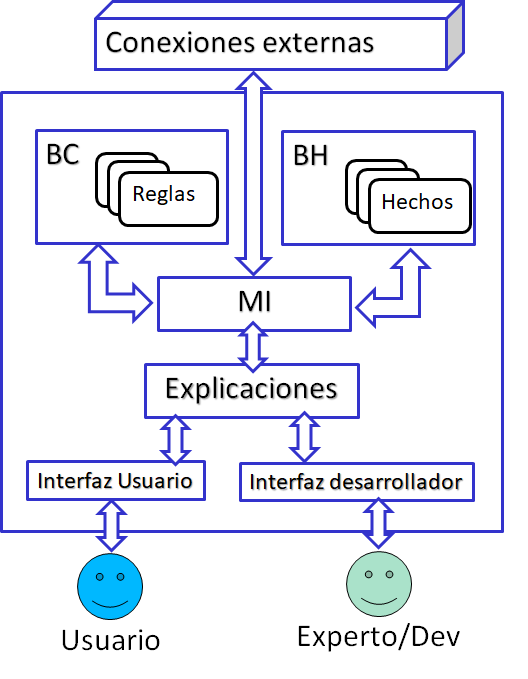

# Primeros pasos en CLIPS


Para poder utilizar CLIPS en Python debemos utilizar la librería *CLIPSPY*. Sin embargo, esta librería no viene instalada por defecto en los entornos de Google Colab por lo que tendremos que instarla manualmente.

In [ ]:
!pip install clipspy

Una vez que hemos instalado CLIPSPY, podemos importar la librería en nuestro programa con `import`.

In [ ]:
import clips

El elemento principal de CLIPSPY es `environment`.
Es un código (estructurado en forma de clase) que encapsula el motor de inferencia y la funcionalidad para interpretar el lenguaje CLIPS.

El `environment` contiene:

*   La base de hechos y su funcionalidad para crear o borrar hechos.
*   La base de conocimiento y su funcionalidad para crear o borrar reglas.
*   El motor de inferencia y su funcionalidad para ajustarlo.

Para crear un environment utilizaremos la función `clips.Environment()`

In [ ]:
# Creamos un entorno para trabajar en CLIPS
env0 = clips.Environment()

env0

## Añadir reglas básicas
Las reglas son la base de cualquier sistema basado en reglas.

Utilizaremos el lenguaje CLIPS para definir las reglas: comando `defrule`.

Las reglas tienen 3 partes:
*   Nombre de la regla.
*   Antecedente: parte izquierda de la regla.
*   Consecuente: parte derecha de la regla.


Introduciremos el código CLIPS mediante una cadena PYTHON utilizando 3 pares de comillas:


`" " " código " " "`


Para crear una regla utilizaremos el comando *defrule*, siguiendo esta notación:

```
(defrule nombre_de_regla
  (PARTE IZQUIERDA)
  =>
  (PARTE DERECHA)
)
```



In [ ]:
# Código en clips para definición de 2 reglas
rule1 = """
(defrule my-rule
  (hecho1 1)
  =>
  (assert(hecho2 2))
)
"""

rule2 = """
(defrule my-rule2
  (hecho2 2)
  =>
  (assert(hecho3 55))
)
"""

El ``assert`` añadido en el consecuente (después del then) lo que hace es añadir un hecho.

Una vez definida una regla debemos de introducirla en nuestro entorno. Hasta que no introduzcamos la regla en nuestro entorno, el sistema basado en conocimiento la desconocerá. Para introducir la regla en un entorno utilizaremos la función `build` contenida en los `environments`.

`env.build()`: función que añade una regla a la base de reglas de un entorno.

Así pues, vamos a añadir las dos reglas definidas anteriormente a nuestro sistema basado en reglas.

In [ ]:
# Añadimos las dos reglas creadas anteriormente
env0.build(rule1)
env0.build(rule2)

Para obtener las reglas almacenadas en un entorno podemos utilizar la función `env.rules()`.

`env.rules()`: función que devuelve todas las reglas a la base de reglas de un entorno.

In [ ]:
# Mostramos las reglas disponibles
for rule in env0.rules():
    print(rule)

(defrule MAIN::my-rule (hecho1 1) => (assert (hecho2 2)))
(defrule MAIN::my-rule2 (hecho2 2) => (assert (hecho3 55)))


### Ejercicio 1

1.1. Crea un nuevo entorno y guárdalo en una variable llamada *entorno_ejercicio1*.

1.2. Añade una regla que: IF *dia lunes* THEN *dia laboral*.

1.3. Añade una regla para si el *dia es sábado* añadir un hecho que indique que el día es no laboral.

1.4. Añade dos reglas que en función de si el día es laboral añadan gimansio abierto o gimnasio cerrado.

1.5. Muestra todas las reglas que hayas añadido.

## Añadir hechos básicos

Los hechos no estructurados nos permiten almacenar hechos simples en la base de hechos.

Normalmente se utilizan para aplicaciones sencillas y hacer pruebas.

No se recomienda para programas complejos. Posteriormente, veremos hechos estructurados.

Algunos ejemplos:

- `(hola)`: un hecho 'hola' sencillo.
- `(edad 22)`: un hecho sencillo 'edad' con un atributo numérico.


Añadimos un hecho sencillo sin un valor

In [ ]:
hechoHola = env0.assert_string("(Hola)")

Añadimos un hecho llamado "hecho1" con el valor "1"

In [ ]:
hecho1 = env0.assert_string("(hecho1 1)")

Podemos mostrar los hechos almacenados en un entorno mediante *env.facts()*.

In [ ]:
for hecho in env0.facts():
  print(hecho)

(Hola)
(hecho1 1)


### Ejercicio 2

Utilizando el entorno *entorno_ejercicio1*:

2.1. Añade el hecho ``(dia vacaciones)``.

2.2. Añade un hecho que represente que el día es sábado.

2.3. Muestra todos los hechos almacenados en el entorno.


# Motor de inferencia

Una vez que tenemos hechos en la base de hechos y reglas en la base de conocimiento, podemos decirle al motor de inferencia que intente aplicar reglas. Para ello, debemos ejecutar la función `env.run()`.

`env.run()` es la función que arranca el motor de inferencia. Una vez ejecutado no parará hasta que no haya más reglas que aplicar. A continuación, tienes un ejemplo:

Mostramos las reglas de la base de conocimiento:

In [ ]:
# Mostramos las reglas disponibles
for rule in env0.rules():
    print(rule)

(defrule MAIN::my-rule (hecho1 1) => (assert (hecho2 2)))
(defrule MAIN::my-rule2 (hecho2 2) => (assert (hecho3 55)))


Mostramos los hechos disponibles en la base de hechos:

In [ ]:
for hecho in env0.facts():
  print(hecho)

(Hola)
(hecho1 1)


Ejecutamos el motor de inferencia:

In [ ]:
env0.run()

2

Oberservamos los cambios en la base de hechos:


In [ ]:
for hecho in env0.facts():
  print(hecho)

(Hola)
(hecho1 1)
(hecho2 2)
(hecho3 55)


## Ejercicio 3

3.1. Si ejecutamos el motor de inferencia en el entorno ``entorno_ejercicio1``, ¿qué reglas deberían activarse? ¿qué hechos se añadirían?

3.2. Ejecuta el motor de inferencia en el entorno ``entorno_ejercicio1``. Tras la ejecución muestra la base de conocimiento y de hechos.

3.3. Vuelve a ejecutar el motor de inferencia en el entorno ``entorno_ejercicio1``. ¿Se ha producido algún cambio?